PROYECTO: Teachable Machine, Practica 1
AUTOR: Adrián Burgos Tomé            FECHA: 06/10/2026

1. DESCRIPCIÓN
   Aplicación web que clasifica imágenes en tiempo real con un modelo
   de Teachable Machine (tipo IMAGEN). La entrada puede ser:
     - La webcam del dispositivo (clasificación continua).
     - Una imagen subida por el usuario (PNG, JPEG o WebP, máx. 5 MB).
   El resultado se muestra como una barra de progreso y un porcentaje
   por cada clase del modelo: [clase 1, clase 2, ...].

   El modelo se carga desde ./modelo y se
   ejecuta en el navegador. Ninguna imagen se envía a un servidor.

2. TECNOLOGÍAS
   - HTML5 / CSS3 / JavaScript (ES2020, sin frameworks)
   - TensorFlow.js 1.3.1         (CDN jsDelivr)
   - @teachablemachine/image 0.8 (CDN jsDelivr)
   - API del navegador: getUserMedia (webcam), URL.createObjectURL

A continuacion se muestra el árbol de directorios usados en este proyecto

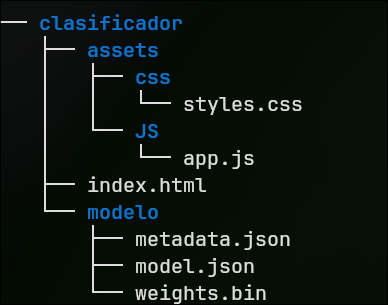

4. FLUJO DE EJECUCIÓN
   - loadModel()      Carga model.json + metadata.json y crea una fila
                       de resultado por clase. Hasta que termina, los
                       controles permanecen desactivados.
   - toggleCamera()   Inicia o detiene la webcam (botón de alternancia).
   - loop()           Con la cámara activa: actualiza el frame y llama
                       a predict() en cada requestAnimationFrame.
   - handleFile()     Valida el archivo (tipo y tamaño), detiene la
                       cámara, muestra la imagen y llama a predict().
   - predict()        Obtiene las probabilidades del modelo.
   - renderResults()  Actualiza etiqueta, barra y % de cada fila.

5. REQUISITOS Y USO
   - Servir el proyecto por HTTP(S): localhost o HTTPS.
     Abrirlo con file:// falla (no carga el modelo ni la cámara).
     Opciones: extensión Live Server, o `python -m http.server`.
   - Aceptar el permiso de cámara cuando el navegador lo solicite.

6. DIRECTIVAS DE SEGURIDAD
   - Los resultados se pintan con textContent (nunca innerHTML).
   - Lista blanca de tipos de archivo y límite de tamaño (5 MB).
   - URL.revokeObjectURL() tras usar cada imagen (evita fugas).
   - Al detener la cámara se libera el dispositivo (webcam.stop()),
     también al cerrar la pestaña.

7. LIMITACIONES
   - La precisión depende de la iluminación y del dataset de entrenamiento.

A continuación se muestra el codigo de los archivos implementados en el proyecto

# Index.html


In [ ]:
<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Reconocimiento de imágenes</title>
  <link rel="stylesheet" href="assets/css/styles.css">
</head>
<body>
  <main class="app">
    <h1>Reconocimiento de imágenes</h1>

    <div class="controls">
      <button id="btn-camera" type="button">Iniciar cámara</button>
      <label class="file-label">
        Subir imagen
        <input id="file-input" type="file" accept="image/png,image/jpeg,image/webp" hidden>
      </label>
    </div>

    <p id="status" role="status" aria-live="polite">Cargando modelo…</p>

    <div id="preview" class="preview"></div>
    <ul id="results" class="results"></ul>
  </main>
<!-- LIbrerias externas javascript-->
  <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.3.1/dist/tf.min.js"></script>
  <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8/dist/teachablemachine-image.min.js"></script>


  <script src="assets/JS/app.js"></script>
</body>
</html>


# styles.css


In [ ]:
:root {
  --bg: black;
  --surface: #1a1d24;
  --text: #e8eaed;
  --accent: green;
  --radius: 10px;
}

* { box-sizing: border-box; }

body {
  margin: 0;
  font-family: system-ui, sans-serif;
  background: var(--bg);
  color: var(--text);
}

.app {
  max-width: 480px;
  margin: 0 auto;
  padding: 1.5rem;
  text-align: center;
}

.controls { display: flex; gap: .5rem; justify-content: center; }

button, .file-label {
  padding: .6rem 1rem;
  border: 0;
  border-radius: var(--radius);
  background: var(--accent);
  color: #fff;
  font-size: 1rem;
  cursor: pointer;
}

.preview {
    margin: 1rem 0;
}


.preview canvas, .preview img {
  max-width: 100%;
  border-radius: var(--radius);
}

.results { list-style: none; padding: 0; margin: 0; }
.results li {
  display: grid;
  grid-template-columns: 1fr 3fr auto;
  gap: .5rem;
  align-items: center;
  padding: .4rem 0;
  text-align: left;
}
.results progress { width: 100%; height: 10px; }

# app.js


In [ ]:
"use strict";

const MODEL_URL = "./modelo/model.json";
const METADATA_URL = "./modelo/metadata.json";
const CAMERA_SIZE = 400;
const MAX_FILE_BYTES = 5 * 1024 * 1024; // 5 MB

const els = {
  btnCamera: document.getElementById("btn-camera"),
  fileInput: document.getElementById("file-input"),
  status: document.getElementById("status"),
  preview: document.getElementById("preview"),
  results: document.getElementById("results"),
};

let model = null;
let webcam = null;
let rafId = null;

/* ---------- Modelo ---------- */

async function loadModel() {
  try {
    model = await tmImage.load(MODEL_URL, METADATA_URL);
    setStatus("Modelo listo.");
    createResultRows(model.getTotalClasses());
  } catch (err) {
    console.error(err);
    setStatus("No se pudo cargar el modelo. ¿Estás usando un servidor local o HTTPS?");
    els.btnCamera.disabled = true;
  }
}

async function predict(source) {
  const predictions = await model.predict(source);
  renderResults(predictions);
}

/* ---------- Cámara ---------- */

async function startCamera() {
  if (webcam) return stopCamera();

  try {
    webcam = new tmImage.Webcam(CAMERA_SIZE, CAMERA_SIZE, true);
    await webcam.setup();
    await webcam.play();
  } catch (err) {
    console.error(err);
    webcam = null;
    setStatus("No se pudo acceder a la cámara (permiso denegado o no disponible).");
    return;
  }

  els.preview.replaceChildren(webcam.canvas);
  els.btnCamera.textContent = "Detener cámara";
  rafId = requestAnimationFrame(loop);
}

async function loop() {
  webcam.update();
  await predict(webcam.canvas);
  rafId = requestAnimationFrame(loop);
}

function stopCamera() {
  if (rafId) cancelAnimationFrame(rafId);
  if (webcam) webcam.stop(); // libera la cámara
  webcam = null;
  rafId = null;
  els.btnCamera.textContent = "Iniciar cámara";
}

/* ---------- Imagen subida ---------- */

async function handleFile(event) {
  const file = event.target.files[0];
  if (!file) return;

  if (!file.type.startsWith("image/") || file.size > MAX_FILE_BYTES) {
    setStatus("Archivo no válido (solo imágenes de hasta 5 MB).");
    return;
  }

  stopCamera();

  const url = URL.createObjectURL(file);
  const img = new Image();
  img.onload = async () => {
    els.preview.replaceChildren(img);
    await predict(img);
    URL.revokeObjectURL(url); // evita fuga de memoria
  };
  img.onerror = () => {
    URL.revokeObjectURL(url);
    setStatus("No se pudo leer la imagen.");
  };
  img.src = url;
}

/* ---------- UI ---------- */

function setStatus(message) {
  els.status.textContent = message;
}

function createResultRows(total) {
  const rows = Array.from({ length: total }, () => {
    const li = document.createElement("li");
    li.append(
      document.createElement("span"),
      document.createElement("progress"),
      document.createElement("span")
    );
    li.querySelector("progress").max = 1;
    return li;
  });
  els.results.replaceChildren(...rows);
}

function renderResults(predictions) {
  predictions.forEach((p, i) => {
    const [label, bar, pct] = els.results.children[i].children;
    label.textContent = p.className; // textContent, nunca innerHTML
    bar.value = p.probability;
    pct.textContent = `${(p.probability * 100).toFixed(1)}%`;
  });
}

/* ---------- Eventos ---------- */

els.btnCamera.addEventListener("click", startCamera);
els.fileInput.addEventListener("change", handleFile);
window.addEventListener("beforeunload", stopCamera);

loadModel();